# Machine Learning Assignment 2: six-phase learning guide
## Worked example: classifying steel plate faults

**Purpose:** an explained, executable reference for learning the required workflow. The assignment permits AI for learning support, not direct copy-paste submissions. Study the implementation, complete the checkpoints, develop your own explanations and changes, and run your work in **BITS Virtual Lab**.

**Execution provenance:** outputs included here were generated in the ChatGPT execution environment, **not BITS Virtual Lab**. They are real reference results, but they do not satisfy the required lab evidence. No GitHub repository or live app has been created for you. No lab screenshot is included.

The notebook preserves the assignment's six steps. The final submission must be one PDF in this order: **(1) repository link, (2) live Streamlit Community Cloud link, (3) one genuine BITS Lab screenshot, (4) full revised README content**. The assignment states a deadline of 8 November 2026, 23:59, without specifying a timezone.

### How to use this notebook

1. Extract `ML_Assignment_2_Learning_Project.zip` and open this notebook **inside `steel_faults_learning/`**, beside `ml_core.py`, `train.py`, and `app.py`.
2. Use a Python 3.12 kernel. In your BITS Lab terminal, install the dependencies with `python -m pip install -r requirements-notebook.txt`. Use the lab's existing notebook interface; do not install a second environment unless needed.
3. Read each explanation, then run its cells in order. The source modules are short enough to inspect alongside the notebook. Rerunning the training cell replaces the generated reference models, test CSV, and result files with your run.
4. Record your actual environment below, complete the reflection prompts, and capture your own lab execution evidence.

In [1]:
from pathlib import Path
import json, sys, platform
import joblib
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
assert (ROOT / "ml_core.py").exists(), "Extract the full project ZIP and open this notebook beside ml_core.py."
from ml_core import (FEATURE_COLUMNS, SOURCE_TARGET_COLUMNS, CLASS_NAMES,
                     MODEL_FILES, build_models, validate_test_frame, evaluate_model)
from prepare_data import prepare_dataset
from train import run_experiment

RANDOM_SEED = 42  # Fix before evaluation; do not search seeds for a better test score.
EXECUTION_CONTEXT = "Reference run in ChatGPT execution environment; not BITS Virtual Lab"
# Change the text above only to describe where you are actually running the work.
print("Python:", platform.python_version())
print("Execution context:", EXECUTION_CONTEXT)

Python: 3.12.14
Execution context: Reference run in ChatGPT execution environment; not BITS Virtual Lab


## Step 1 - Choose and understand one dataset

**Source:** [UCI Steel Plates Faults](https://archive.ics.uci.edu/dataset/198/steel+plates+faults), DOI [10.24432/C5J88N](https://doi.org/10.24432/C5J88N). Attribution: Buscema, M., Terzi, S., and Tastle, W. (2010); licensed CC BY 4.0.

The public dataset has **1,941 instances and 27 numeric input features**, exceeding the minimums of 500 instances and 12 features. Its seven classes describe different steel defects. Inputs summarize shape, location, luminosity, edges, and material characteristics. This is a tabular classification exercise using measured features; it does not train directly on raw images.

The original archive contains **27 feature columns plus 7 class indicator columns**. Exactly one class indicator is active per row. `prepare_data.py` checks that rule, converts the indicators into the categorical `target` column, and excludes **all seven original indicator columns from X**. Keeping any of those columns in X would leak the answer.

The original label `K_Scatch` is preserved for consistent training and upload labels. Do not silently change it to a different spelling in test CSVs.

In [2]:
data = prepare_dataset(ROOT)
manifest = json.loads((ROOT / "data/dataset_manifest.json").read_text())
print(f"Rows: {len(data):,}; features: {len(FEATURE_COLUMNS)}; classes: {data.target.nunique()}")
print("Missing cells:", manifest["missing_cells"])
print("Duplicate feature rows:", manifest["duplicate_feature_rows"])
assert len(data) >= 500 and len(FEATURE_COLUMNS) >= 12
assert not set(SOURCE_TARGET_COLUMNS).intersection(FEATURE_COLUMNS)
display(data[["Pixels_Areas", "X_Perimeter", "Y_Perimeter", "Luminosity_Index", "target"]].head())
counts = data.target.value_counts().reindex(CLASS_NAMES)
display(pd.DataFrame({"Class": counts.index, "Examples": counts.values,
                      "Share (%)": (100 * counts.values / len(data)).round(2)}))

Rows: 1,941; features: 27; classes: 7
Missing cells: 0
Duplicate feature rows: 0


,Pixels_Areas,X_Perimeter,Y_Perimeter,Luminosity_Index,target
0,267,17,44,-0.2913,Pastry
1,108,10,30,-0.1756,Pastry
2,71,8,19,-0.1228,Pastry
3,176,13,45,-0.1568,Pastry
4,2409,60,260,-0.1992,Pastry


,Class,Examples,Share (%)
0,Bumps,402,20.71
1,Dirtiness,55,2.83
2,K_Scatch,391,20.14
3,Other_Faults,673,34.67
4,Pastry,158,8.14
5,Stains,72,3.71
6,Z_Scratch,190,9.79


### Learning checkpoint 1

Write your own answers before proceeding:

- Why is `target` excluded from the 27-feature count?
- Why must all seven original class indicators be removed after converting them to one target?
- Which class has the fewest examples, and why can overall accuracy hide poor performance on that class?
- Why does this industrial inspection dataset interest you? Explain in your own words.

**Your answers:** _Add your own reasoning here._

## Step 2 - Train all five models and calculate six metrics

### 2A. Fix one training/test split

Use a stratified 80/20 split with seed 42. All models use the same **1,552 training rows and 389 test rows**. Stratification preserves approximately the class proportions. The small class counts also mean that a few mistakes can change a class's recall substantially.

The held-out test data is exported in raw feature units to `test_data.csv`, including the true `target` labels. The training code records source row identities separately in `results/split_membership.csv`; row IDs are not model inputs.

In [3]:
from sklearn.model_selection import train_test_split
train_idx, test_idx = train_test_split(
    np.arange(len(data)), test_size=0.20,
    random_state=RANDOM_SEED, stratify=data["target"])
X_train, y_train = data.iloc[train_idx][FEATURE_COLUMNS], data.iloc[train_idx]["target"]
X_test, y_test = data.iloc[test_idx][FEATURE_COLUMNS], data.iloc[test_idx]["target"]
assert set(train_idx).isdisjoint(test_idx)
print("Training rows:", len(X_train), "Test rows:", len(X_test))
display(pd.DataFrame({
    "Train": y_train.value_counts(), "Test": y_test.value_counts()
}).reindex(CLASS_NAMES))

Training rows: 1552 Test rows: 389


,Train,Test
target,,
Bumps,321,81
Dirtiness,44,11
K_Scatch,313,78
Other_Faults,538,135
Pastry,126,32
Stains,58,14
Z_Scratch,152,38


### 2B. Preprocessing and the five baselines

The source has no missing values. This reference accepts only complete numeric features and rejects missing/nonfinite values rather than silently dropping rows. If you add imputation in your own work, fit it on training data only.

For Logistic Regression, KNN, SVM, and Gaussian NB, each pipeline includes `StandardScaler`. For a feature, $z=(x-\mu_{train})/\sigma_{train}$. Scaling matters especially for distances and regularized margins. Scaling is not necessary for the tree; Gaussian NB is approximately invariant to simple feature rescaling except for numerical smoothing effects, but a scaled pipeline is used consistently here.

**Do not fit a scaler on the full dataset before splitting.** During cross-validation, each pipeline is cloned and fitted on that fold's training data. Saved pipelines include their fitted scaler, so the app can use raw features without fitting anything again. See scikit-learn's [preprocessing and leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html).

| Model | Fixed baseline settings | What it learns |
|---|---|---|
| Logistic Regression | C=1, max_iter=5000 | Linear class decision boundaries |
| Decision Tree | max_depth=10, min_samples_leaf=3 | A sequence of feature-threshold decisions |
| KNN | k=7, distance weighting | Local class evidence from nearby training examples |
| Gaussian Naive Bayes | var_smoothing=1e-9 | Class likelihoods under feature-wise Gaussian assumptions |
| SVM | RBF kernel, C=10, gamma=scale, probability=True | Nonlinear separating boundaries |

These are preselected baseline settings, not an exhaustive optimization. Gaussian NB is used because the predictors are numeric measurements rather than word counts. Its independence and distribution assumptions are approximations for these features.

In [4]:
import inspect
print(inspect.getsource(build_models))

def build_models(seed: int = 42) -> dict[str, Pipeline]:
    """Fixed, documented baselines; settings are not tuned on the test set.

    A Pipeline fits its scaler only when the training code calls fit(). Each CV
    fold therefore learns its own training-fold mean and standard deviation.
    Tree thresholds do not need standardized feature units.
    """
    def scaled(classifier):
        return Pipeline([("scale", StandardScaler()), ("classifier", classifier)])

    return {
        "Logistic Regression": scaled(LogisticRegression(C=1.0, max_iter=5000)),
        "Decision Tree": Pipeline([("classifier", DecisionTreeClassifier(
            max_depth=10, min_samples_leaf=3, random_state=seed))]),
        "KNN": scaled(KNeighborsClassifier(n_neighbors=7, weights="distance")),
        "Naive Bayes": scaled(GaussianNB(var_smoothing=1e-9)),
        "Support Vector Machine": scaled(SVC(
            C=10.0, kernel="rbf", gamma="scale", probability=True, random_state=seed)),
    }



### 2C. Define the metric conventions once

For a class $k$, treat that class as positive and all other classes as negative:

$$P_k=\frac{TP_k}{TP_k+FP_k},\quad R_k=\frac{TP_k}{TP_k+FN_k},\quad F1_k=\frac{2P_kR_k}{P_k+R_k}.$$

**Accuracy** is the number of correctly classified rows divided by the total rows. **Macro precision, recall, and F1** are the unweighted means of the corresponding seven class-specific metrics. Macro F1 is the mean of the seven F1 scores, not the harmonic mean of macro precision and macro recall. Undefined class precision/recall/F1 values are assigned zero consistently using `zero_division=0`.

**AUC** is macro one-versus-rest ROC-AUC, computed from the seven probability columns returned by `predict_proba`. Each probability column must match the class at the same position in `pipeline.classes_`. Do not calculate AUC from hard predicted class labels. See the [ROC-AUC API](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html).

**MCC** uses the multiclass Matthews correlation coefficient. If $C$ is the confusion matrix, $c=\mathrm{trace}(C)$, $s$ is the total number of samples, $t_k$ is a row sum and $p_k$ a column sum:

$$MCC=\frac{cs-\sum_k p_k t_k}{\sqrt{(s^2-\sum_k p_k^2)(s^2-\sum_k t_k^2)}}.$$

Use `matthews_corrcoef` rather than manually extending a binary-only formula. See the [MCC API](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.matthews_corrcoef.html).

The app averages P/R/F1 over the same seven labels even when an uploaded file omits a class. It displays **AUC = N/A** when any expected class has no true examples, because the chosen all-seven-class OvR AUC is then undefined. The full supplied test set contains all seven classes.

### 2D. Cross-validate on training data, then fit and evaluate

Within the 1,552 training rows, use five-fold stratified cross-validation and record macro F1 for each model. Select the preferred baseline by the highest mean CV macro F1. Fit every baseline on all training rows, evaluate each once on the held-out set, and save each full pipeline.

The training function follows this order:

```python
for name, pipeline in build_models(seed).items():
    fold_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring=scorer)
    pipeline.fit(X_train, y_train)
    outcome = evaluate_model(pipeline, X_test, y_test)
    joblib.dump(pipeline, model_path)
```

The next cell performs the actual reference computation. It also regenerates the test CSV, comparisons, reports, predictions, matrices, and metadata. It does **not** create BITS execution evidence just by writing an environment label.

In [5]:
comparison = run_experiment(
    ROOT, seed=RANDOM_SEED, cv_folds=5, execution_context=EXECUTION_CONTEXT)
display(comparison.round(4))

Execution context: Reference run in ChatGPT execution environment; not BITS Virtual Lab
Dataset: 1941 rows; 27 features; 7 classes
Stratified split: 1552 train / 389 test; seed=42
Evaluating training folds and fitting Logistic Regression...
Evaluating training folds and fitting Decision Tree...
Evaluating training folds and fitting KNN...
Evaluating training folds and fitting Naive Bayes...
Evaluating training folds and fitting Support Vector Machine...

Held-out test metrics (macro P/R/F1; macro OvR AUC):
         ML Model Name  Accuracy    AUC  Precision  Recall     F1    MCC
   Logistic Regression    0.7275 0.9379     0.7613  0.7305 0.7418 0.6487
         Decision Tree    0.7481 0.9056     0.7784  0.7364 0.7551 0.6728
                   KNN    0.7558 0.9251     0.7453  0.7687 0.7546 0.6884
           Naive Bayes    0.6093 0.9225     0.6333  0.7169 0.6339 0.5484
Support Vector Machine    0.7635 0.9566     0.8018  0.7674 0.7810 0.6949

Preferred baseline from training-only CV: Support

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.7275,0.9379,0.7613,0.7305,0.7418,0.6487
1,Decision Tree,0.7481,0.9056,0.7784,0.7364,0.7551,0.6728
2,KNN,0.7558,0.9251,0.7453,0.7687,0.7546,0.6884
3,Naive Bayes,0.6093,0.9225,0.6333,0.7169,0.6339,0.5484
4,Support Vector Machine,0.7635,0.9566,0.8018,0.7674,0.7810,0.6949


Preferred baseline selected from training-only CV: Support Vector Machine
Selection rule: Highest mean 5-fold stratified training-only CV macro F1 among fixed baselines; no test tuning.


,ML Model Name,CV macro F1 mean,CV macro F1 std,Training accuracy
0,Logistic Regression,0.7220,0.0263,0.7339
1,Decision Tree,0.7379,0.0132,0.8505
2,KNN,0.7676,0.0222,1.0000
3,Naive Bayes,0.6153,0.0264,0.5999
4,Support Vector Machine,0.7760,0.0187,0.8860


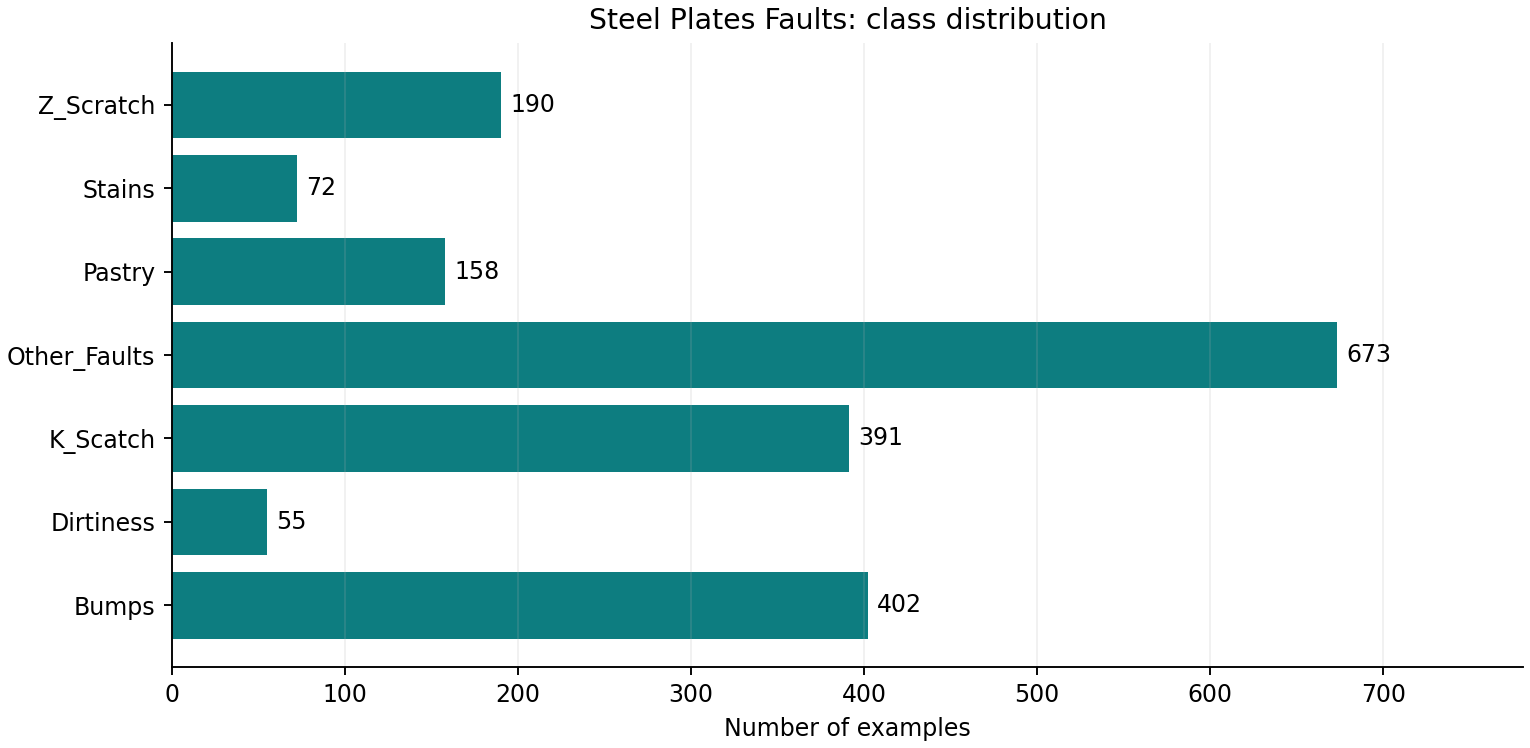

In [6]:
cv_results = pd.read_csv(ROOT / "results/cv_results.csv")
metadata = json.loads((ROOT / "model/metadata.json").read_text())
display(cv_results[["ML Model Name", "CV macro F1 mean", "CV macro F1 std", "Training accuracy"]].round(4))
print("Preferred baseline selected from training-only CV:", metadata["chosen_model"])
print("Selection rule:", metadata["selection_rule"])
display(Image(filename=str(ROOT / "results/class_distribution.png")))

### 2E. Inspect actual errors, not only the overall table

In the verified reference run, SVM has the highest training CV mean macro F1 (approximately **0.7760**) and the highest test macro F1 (**0.7810**). Its test accuracy is **0.7635**, meaning 297 of the 389 held-out examples are correct. KNN has slightly higher test macro recall than SVM, so the preferred model does not win every metric.

SVM and KNN CV scores are close; the fold standard deviations are descriptive and do not prove a statistically significant ranking. Treat SVM as the preferred baseline under this split and objective, not a universally best classifier.

The following cell loads the **saved** SVM and recomputes the test results. It does not refit the model. This is the same path the Streamlit app follows.

In [7]:
chosen = metadata["chosen_model"]
saved_model = joblib.load(ROOT / "model" / MODEL_FILES[chosen])
test_frame = pd.read_csv(ROOT / "test_data.csv")
X_uploaded, y_uploaded = validate_test_frame(test_frame)
evaluated = evaluate_model(saved_model, X_uploaded, y_uploaded)
expected = comparison.set_index("ML Model Name").loc[chosen]
for metric, value in evaluated["metrics"].items():
    assert np.isclose(value, expected[metric]), metric
print("Saved-model evaluation reproduces all six metrics.")
class_report = pd.DataFrame.from_dict(
    {label: row for label, row in evaluated["report"].items() if isinstance(row, dict)},
    orient="index")
display(class_report.round(4))

Saved-model evaluation reproduces all six metrics.


,precision,recall,f1-score,support
Bumps,0.6706,0.7037,0.6867,81.0
Dirtiness,1.0000,0.7273,0.8421,11.0
K_Scatch,0.9867,0.9487,0.9673,78.0
Other_Faults,0.6884,0.7037,0.6960,135.0
Pastry,0.6207,0.5625,0.5902,32.0
Stains,0.8000,0.8571,0.8276,14.0
Z_Scratch,0.8462,0.8684,0.8571,38.0
macro avg,0.8018,0.7674,0.7810,389.0
weighted avg,0.7672,0.7635,0.7644,389.0


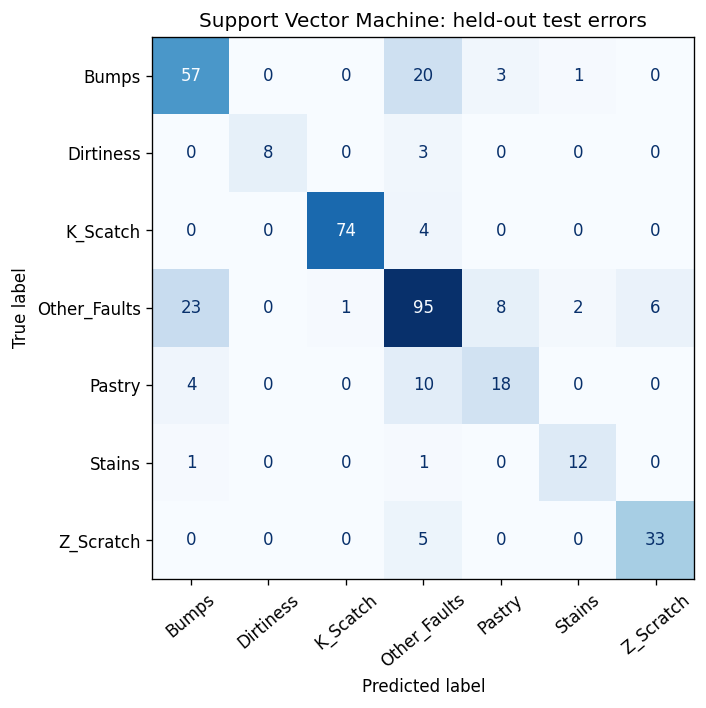

In [13]:
from io import BytesIO
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(evaluated["confusion_matrix"], display_labels=evaluated["classes"]).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=40)
ax.set_title(f"{chosen}: held-out test errors")
plt.tight_layout()
# Explicit PNG display also works when training code selects the Agg backend.
figure_buffer = BytesIO()
fig.savefig(figure_buffer, format="png", dpi=120, bbox_inches="tight")
display(Image(data=figure_buffer.getvalue()))
plt.close(fig)

### Worked class-wise calculation: Dirtiness

For the reference SVM, Dirtiness has **8 true positives, 0 false positives, and 3 false negatives**. Therefore precision is $8/(8+0)=1.0000$, recall is $8/(8+3)=0.7273$, and F1 is $16/(16+0+3)=0.8421$. High precision does not imply that every actual defect was found.

The code below computes these counts from the confusion matrix for every class. Rows represent actual labels and columns predicted labels.

In [9]:
cm = np.asarray(evaluated["confusion_matrix"])
tp = np.diag(cm)
fp = cm.sum(axis=0) - tp
fn = cm.sum(axis=1) - tp
tn = cm.sum() - tp - fp - fn
manual = pd.DataFrame({"TP": tp, "FP": fp, "FN": fn, "TN": tn}, index=evaluated["classes"])
manual["Precision"] = np.divide(tp, tp + fp, out=np.zeros(7, dtype=float), where=tp + fp != 0)
manual["Recall"] = np.divide(tp, tp + fn, out=np.zeros(7, dtype=float), where=tp + fn != 0)
manual["F1"] = np.divide(2 * tp, 2 * tp + fp + fn, out=np.zeros(7, dtype=float), where=2 * tp + fp + fn != 0)
display(manual.round(4))
assert np.isclose(manual["F1"].mean(), evaluated["metrics"]["F1"])

,TP,FP,FN,TN,Precision,Recall,F1
Bumps,57,28,24,280,0.6706,0.7037,0.6867
Dirtiness,8,0,3,378,1.0000,0.7273,0.8421
K_Scatch,74,1,4,310,0.9867,0.9487,0.9673
Other_Faults,95,43,40,211,0.6884,0.7037,0.6960
Pastry,18,11,14,346,0.6207,0.5625,0.5902
Stains,12,3,2,372,0.8000,0.8571,0.8276
Z_Scratch,33,6,5,345,0.8462,0.8684,0.8571


### Learning checkpoint 2: your model analysis

1. Explain why the tree's training accuracy is higher than its held-out accuracy. What would you investigate before claiming overfitting?
2. Distance-weighted KNN predicts training points using the training set containing those very points. Why is its 1.0 resubstitution accuracy a weak measure of generalization?
3. Why can Gaussian NB have AUC above 0.9 and much lower classification accuracy? Distinguish probability ranking from final class assignment.
4. For the preferred model, find the two most frequent off-diagonal errors. Explain what these errors suggest you should investigate.
5. Which would matter more for your chosen industrial use case: missed faults of a particular class, false alarms, or overall accuracy? Justify the metric you would prioritize.

**Your discussion:** _Write your own interpretation using exact counts from your run._

### Optional original experiment

Decide on a hypothesis before running it. Examples: compare logistic-regression regularization strengths using training-only CV, compare tree depths using training-only CV, or compare class-weight settings. Keep the held-out split fixed and do not use test metrics to choose settings. The cell below is deliberately disabled until you choose to run and explain it.

In [10]:
RUN_MY_EXPERIMENT = False
if RUN_MY_EXPERIMENT:
    from sklearn.model_selection import GridSearchCV, StratifiedKFold
    from sklearn.metrics import make_scorer, f1_score
    scorer = make_scorer(f1_score, average="macro", labels=CLASS_NAMES, zero_division=0, pos_label=None)
    search = GridSearchCV(
        build_models(RANDOM_SEED)["Logistic Regression"],
        {"classifier__C": [0.1, 1.0, 10.0]}, scoring=scorer,
        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_SEED),
        n_jobs=1, refit=True)
    search.fit(X_train, y_train)
    display(pd.DataFrame(search.cv_results_)[["param_classifier__C", "mean_test_score", "std_test_score"]])
    print("Chosen using training folds:", search.best_params_)
else:
    print("Optional experiment skipped. Write your hypothesis before enabling it.")

Optional experiment skipped. Write your hypothesis before enabling it.


## Step 3 - Prepare your GitHub repository

The provided files illustrate the required structure. Your repository must contain your own understood and adapted implementation, not an unexamined copy of this reference.

| Path | Purpose |
|---|---|
| `app.py` | Streamlit evaluation frontend |
| `requirements.txt` | Tested deployment dependencies |
| `README.md` | Required a-d structure, metrics, observations, and actual links |
| `test_data.csv` | Same held-out rows with 27 features plus target |
| `model/*.joblib` | All five fitted classifiers including preprocessing |
| `model/metadata.json` | Classes, feature order, versions, split, selection, execution context |
| `ml_core.py` | Model definitions, input validation, metrics |
| `prepare_data.py` | UCI source conversion without target leakage |
| `train.py` | Training, CV, evaluation, and export |
| `data/` | Public source archive, prepared CSV, and provenance |
| `results/` | Comparisons, class reports, predictions, and figures |
| This notebook | Phase explanations and your experiment record |

Create your own GitHub repository and commit actual work as you complete the phases. Keep secrets, caches, and virtual environments out of the repository; keep `model/` and `test_data.csv` in it. Verify the files on GitHub itself after uploading. Large source datasets are not required here because this public dataset is small.

Terminal example after your own implementation is ready (replace the remote with your real URL):

```bash
git init
git add .
git commit -m "Implement and document steel fault classifier experiments"
git branch -M main
git remote add origin YOUR_REAL_GITHUB_REPOSITORY_URL
git push -u origin main
```

No commands in this notebook create a repository or send code to an external account.

In [11]:
required = ["app.py", "requirements.txt", "README.md", "test_data.csv", "train.py", "ml_core.py"]
required += [f"model/{filename}" for filename in MODEL_FILES.values()]
display(pd.DataFrame({"Required file": required, "Exists": [(ROOT / p).is_file() for p in required]}))

,Required file,Exists
0,app.py,True
1,requirements.txt,True
2,README.md,True
3,test_data.csv,True
4,train.py,True
5,ml_core.py,True
6,model/logistic_regression.joblib,True
7,model/decision_tree.joblib,True
8,model/knn.joblib,True
9,model/naive_bayes.joblib,True


## Step 4 - Create and verify requirements.txt

The reference was tested with Python 3.12 and the versions below. The same scikit-learn and numeric-library versions should be used when training and loading saved models. A version mismatch may require retraining, not simply ignoring a warning. See [scikit-learn model persistence](https://scikit-learn.org/stable/model_persistence.html).

In the BITS Lab terminal:

```bash
python --version
python -m pip install -r requirements.txt
python train.py --execution-context "BITS Virtual Lab"
python -m streamlit run app.py
```

Use the BITS label only for an actual run inside the lab. If the lab has a different required Python version, use compatible dependencies, test them, retrain, and update requirements accordingly. `requirements-notebook.txt` adds tools for this notebook; Community Cloud needs only `requirements.txt`.

In [12]:
print((ROOT / "requirements.txt").read_text())
print("Saved-model package versions:")
display(pd.DataFrame(metadata["package_versions"].items(), columns=["Package", "Training version"]))

# Tested reference environment: Python 3.12. Use the same ML versions for saved models.
streamlit==1.52.0
scikit-learn==1.8.0
numpy==2.3.5
pandas==2.2.3
scipy==1.17.0
joblib==1.5.3
matplotlib==3.10.8

Saved-model package versions:


,Package,Training version
0,numpy,2.3.5
1,pandas,2.2.3
2,scipy,1.17.0
3,scikit-learn,1.8.0
4,joblib,1.5.3
5,matplotlib,3.10.8


## Step 5 - Write README.md in the exact requested structure

Use these headings in order:

**a. Problem statement** - Explain what is classified and why it is useful.

**b. Dataset description** - Identify the public source, size, inputs, target classes, class imbalance, and preprocessing.

**c. GitHub Repository Link** - Insert your real, working repository URL. Add your actual deployed app URL as well.

**d. Models used** - Include the five-row/six-metric comparison, state averaging conventions, describe settings, and add observations for each model plus the overall preferred model.

The supplied README is an annotated reference with real reference metrics and explicitly pending links. Replace the discussion with your own evidence-based explanation after your BITS run. Include the **full final README content** in your submission PDF, not just a link or screenshot of the README.

### Evidence-based observations to examine

- Logistic Regression achieves 0.7418 macro F1 in the reference; 30 of the 81 Bumps examples become Other_Faults.
- Decision Tree achieves 0.7551 macro F1 and high K_Scatch recall (74/78), but identifies only 12/32 Pastry examples.
- KNN achieves 0.7546 macro F1 and the highest reference macro recall (0.7687); it finds 36/38 Z_Scratch examples.
- Gaussian NB achieves 0.6339 macro F1 and recognizes only 34/135 Other_Faults examples. Correlated features or mismatched class distributions are hypotheses to investigate, not established causes of the error.
- SVM achieves 0.7810 macro F1 and 0.9566 AUC. It is also the CV-selected baseline, but still confuses Bumps and Other_Faults.

These are examples of how to connect claims to numbers. Your own observations should explain your own run and its limitations. Do not claim the row-level split proves performance on unseen plants, cameras, or production lines.

## Step 6 - Run and deploy the Streamlit application

### Local/lab verification

Run `python -m streamlit run app.py` from the project directory. Use the URL displayed by Streamlit through your lab's supported browser/port access. The app includes:

- A **test CSV upload** requiring 27 feature columns plus the real target.
- A **model dropdown** covering all five saved classifiers.
- **All six metrics** for the selected model and a comparison table for all five on the same uploaded rows.
- A **confusion matrix and classification report**, plus errors and prediction downloads.

The evaluation path is **CSV validation -> load saved pipeline -> predict/predict_proba -> calculate metrics -> display**. There is no `.fit()` call in the app. Uploading a CSV must never retrain the model or refit its scaler.

Check every dropdown choice and upload the full `test_data.csv`. Compare app scores against `results/comparison.csv`. Try a missing target column: the app should show a readable validation message. A file missing some classes should show AUC as N/A with an explanation.

### Streamlit Community Cloud deployment

1. Open [Streamlit Community Cloud](https://streamlit.io/cloud) and sign in with your GitHub account.
2. Choose **Create app** (called New App in the assignment), select your actual repository and branch, and set the entrypoint to `app.py`.
3. Under **Advanced settings**, select Python **3.12**, matching the reference. Keep your own tested training/deployment versions aligned.
4. Deploy and inspect logs if dependencies or files are missing.
5. Open the real app URL, exercise upload and model selection, and check evaluator access from a signed-out/private window.

Official instructions: [Streamlit deployment](https://docs.streamlit.io/deploy/streamlit-community-cloud/deploy-your-app/deploy) and [dependencies](https://docs.streamlit.io/deploy/concepts/dependencies).

No deployment is performed by this notebook. A working local application is not yet a live Community Cloud submission.

## Final submission - assemble one PDF after the genuine work is complete

Maintain this exact order:

1. **GitHub repository link**, clickable and opening the required files.
2. **Live Streamlit Community Cloud app link**, clickable and opening the interactive frontend.
3. **One screenshot of your assignment executing in BITS Virtual Lab.** Show the lab context and meaningful execution/results. Take this from your real lab session; the reference results here are not lab evidence.
4. **Full final README content**, including dataset description, the comparison table, all five observations, and your overall winner.

You can assemble this in Word, Google Docs, or the lab's document editor and export as PDF. Click both links in the exported PDF. Check that tables are readable, the screenshot is legible, and no pending placeholders remain. Then use the course's actual **Submit** action; the assignment says drafts are not accepted.

### Your completion record

| Item | Your actual evidence |
|---|---|
| Personal implementation and explanation | _Complete your checkpoints and justified experiment_ |
| BITS Lab execution | _Date/time and genuine screenshot_ |
| GitHub repository | _Your real URL_ |
| Streamlit app | _Your real URL_ |
| Final README | _Updated using your actual results and discussion_ |
| Final PDF | _One PDF, exact required order, tested links_ |

**Remaining work is intentional:** this is a learning package. The personal account links, lab evidence, student-authored discussion, and final course submission must be completed by you.